In [177]:
import os
from pathlib import Path

if Path.cwd().name == "other_experiments":
    os.chdir("..")
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import py_files.configs.config as cfg
import py_files.configs.comon as comon
from py_files.functions import get_gamma_array, get_tau_array

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [178]:


from py_files.configs.config import CONFIG_PARAMETRS


times = cfg.TIME_VECTOR
radius = 2 
x = radius*np.sin(2*np.pi*times)
y = radius*np.cos(2*np.pi*times)
M = 10
gamma_arr = get_gamma_array(M)
configs = cfg.CONFIG_PARAMETRS.copy()
configs["R"] = 2
configs["M"] = M
tau_arr = list(get_tau_array(configs)*1e3) # Микросекунды
tau_mks =  [ round(float(tau),1) for tau in tau_arr]

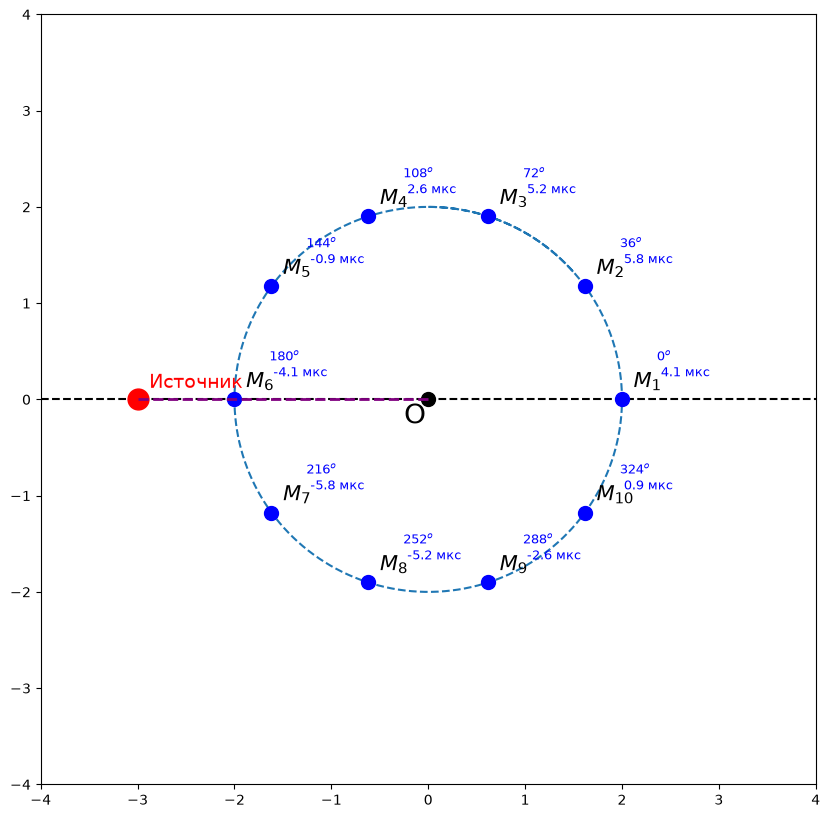

In [179]:
from matplotlib import style
from matplotlib.cm import Blues


fig, ax = plt.subplots(1,1,figsize = (10,10))

ax.plot(x,y, linestyle = "--")
ax.grid(False)
ax.set_xlim(-2*radius, 2*radius)
ax.set_ylim(-2*radius, 2*radius)
#ax.axline((0,0), (0,1), color = "black", linestyle = "--")
ax.axline((0,0), (1,0), color = "black", linestyle = "--")
ax.plot(0,0, marker = "o",  markersize=10, color='black')
plt.text(-0.25, -0.25, 'O', fontsize=20, color='black')
for idx, value in enumerate(gamma_arr):
    d = 0.12
    x1 = radius*np.cos(value); y1 = radius*np.sin(value)
    ax.plot(x1,y1, marker = "o",  markersize=10, color='blue')
    plt.text(x1+d, y1+d, rf"$M_{{{idx+1}}}$", fontsize=15, color='black')
    v = int(value*(180/np.pi))
    plt.text(x1+3*d, y1+2*d, f"${v}^o$\n {tau_mks[idx]} мкс", fontsize=9, color="blue")

x2 = 3*np.cos(comon.TARGET_PHI); y2 = 3*np.sin(comon.TARGET_PHI)
ax.plot(x2, y2, marker = "o", markersize=15, color='red')
ax.text(x2+d,y2+d, "Источник", fontsize  = 14,  color = "red")
ax.plot([0,x2], [0,y2], color='purple', linestyle = "--", linewidth=2)
